# A/B positions and returns: 2026

Read the two CSV files from `data/` and keep prices from 2026-01-01 onward. Construct A and B at the first trading day's Open, then value the fixed shares at each daily Close. All paths are relative to the project folder.

## Backtest assumptions

- **Close-only models:** correlation, cointegration, ADF and all hedge regressions use vendor Close. No adjusted-price field or adjustment-factor conversion is used.
- **Execution and valuation:** initial entry and rebalance fills use Open; daily positions and P&L use Close from `auto_adjust=False` data.
- **Coefficient choice:** `beta_column="beta"` uses the fixed 2022-2025 Close OLS slope. `beta_column="quote_beta"` refits Close OLS over an expanding window from each pair's formation start through the last trading Close before entry/rebalance. For example, an April 1 execution uses data through March 31. Regression includes an intercept. Cointegration screening is not repeated during rebalancing.
- **Dividend cash flows excluded:** ignore long dividend/distribution receipts, short dividend/distribution compensation payments, reinvestment and associated taxes. SPY uses the same assumption. This exclusion does not assume the two sides' cash flows cancel.
- **Price-only results:** ex-dividend price movements remain in Close prices. P&L, realized losses and returns are price-only, not total returns including distributions. Borrow fees and transaction costs remain zero.


In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display
from positions import construct_portfolios, calculate_daily_positions, PortfolioRebalancer
from risk import BetaAnalysis, RiskAnalysis
%matplotlib inline
import matplotlib.pyplot as plt

DATA_DIR = Path("data")
START_DATE = "2026-01-01"

prices = pd.read_csv(
    DATA_DIR / "portfolios_open_close.csv",
    header=[0, 1], index_col=0, parse_dates=True,
).sort_index()
pair_betas = pd.read_csv(DATA_DIR / "pair_betas.csv")
assert pair_betas["price_basis"].eq("Close").all(), "Run the Close-only data notebook first."
close_history = prices.xs("Close", axis=1, level="Price").copy()

# Filter in memory; preserve the full history in the source CSV.
open_close = prices.loc[START_DATE:].copy()
if open_close.empty:
    raise ValueError("No Open/Close data on or after " + START_DATE)
if "SPY" not in open_close.columns.get_level_values("Ticker"):
    raise ValueError("SPY is missing. Run data.ipynb with benchmark_ticker='SPY' first.")

assert open_close.index.min() >= pd.Timestamp(START_DATE)
print("Analysis dates:", open_close.index.min().date(), "to", open_close.index.max().date())
print("Trading dates:", len(open_close), "Price columns:", len(open_close.columns))

Analysis dates: 2026-01-02 to 2026-10-20
Trading dates: 201 Price columns: 62


## A/B/C underlying assets and formation betas

Read the original A/B/C underlying assets from `pair_betas.csv`: A is the AB row's `y_ticker`, B is its `x_ticker`, and C is the AC row's `x_ticker`. Each row of `portfolio_underlyings` shows one matching A/B/C group. Check the BC rows for consistency. These are the original asset groups; actual long/short holdings can change after rebalancing. AB is A ~ B, AC is A ~ C and BC is B ~ C. `portfolio_open_close` exposes each portfolio's constituent Open/Close data from 2026 onward. `pair_betas` retains the coefficients estimated from 2022-2025; no regression is fitted to 2026 prices.

In [2]:
ab_pairs = pair_betas.loc[pair_betas["pair"].eq("AB")].set_index("anchor_A")
ac_pairs = pair_betas.loc[pair_betas["pair"].eq("AC")].set_index("anchor_A")
bc_pairs = pair_betas.loc[pair_betas["pair"].eq("BC")].set_index("anchor_A")
assert ab_pairs.index.is_unique and ac_pairs.index.is_unique and bc_pairs.index.is_unique
assert set(ab_pairs.index) == set(ac_pairs.index) == set(bc_pairs.index)
ac_pairs = ac_pairs.reindex(ab_pairs.index)
bc_pairs = bc_pairs.reindex(ab_pairs.index)
assert ab_pairs["y_ticker"].equals(ac_pairs["y_ticker"])
assert ab_pairs["x_ticker"].equals(bc_pairs["y_ticker"])
assert ac_pairs["x_ticker"].equals(bc_pairs["x_ticker"])

portfolio_tickers = {
    "A": ab_pairs["y_ticker"].tolist(),
    "B": ab_pairs["x_ticker"].tolist(),
    "C": ac_pairs["x_ticker"].tolist(),
}
portfolio_open_close = {
    name: open_close.loc[:, tickers].copy()
    for name, tickers in portfolio_tickers.items()
}

assert all("SPY" not in tickers for tickers in portfolio_tickers.values())
portfolio_underlyings = pd.DataFrame(portfolio_tickers)
display(portfolio_underlyings)
display(pair_betas[["anchor_A", "pair", "y_ticker", "x_ticker", "alpha", "beta", "quote_beta"]])

,A,B,C
0,NVDA,ANET,NVMI
1,AAPL,DAKT,BELFA
2,MSFT,UBER,CDNS
3,TSM,AVGO,FLEX
4,BRK-B,AIG,FNF
5,JPM,BLX,MFG
6,V,MUFG,SEIC
7,MA,HLI,BAM
8,PLTR,NYAX,NET
9,ORCL,INOD,GWRE


,anchor_A,pair,y_ticker,x_ticker,alpha,beta,quote_beta
0,NVDA,AB,NVDA,ANET,-26.080030,1.563592,1.563592
1,NVDA,AC,NVDA,NVMI,-48.851525,0.781103,0.781103
2,NVDA,BC,ANET,NVMI,-11.953617,0.483638,0.483638
3,AAPL,AB,AAPL,DAKT,130.460278,6.279021,6.279021
4,AAPL,AC,AAPL,BELFA,128.100684,1.005278,1.005278
5,AAPL,BC,DAKT,BELFA,0.196881,0.151049,0.151049
6,MSFT,AB,MSFT,UBER,165.153029,3.561458,3.561458
7,MSFT,AC,MSFT,CDNS,53.441146,1.274181,1.274181
8,MSFT,BC,UBER,CDNS,-27.135621,0.340571,0.340571
9,TSM,AB,TSM,AVGO,50.326848,0.667354,0.667354


## Open, Close and SPY

`open_prices` and `close_prices` contain one column per ticker. `spy_open_close` contains the benchmark Open/Close data for the same analysis period.

In [3]:
open_prices = open_close.xs("Open", axis=1, level="Price").copy()
close_prices = open_close.xs("Close", axis=1, level="Price").copy()
spy_open_close = open_close["SPY"].copy()

display(open_close.head())
display(spy_open_close.head())

Ticker            NVDA                    AAPL                    MSFT  \
Price             Open       Close        Open       Close        Open   
Date                                                                     
2026-01-02  189.839996  188.850006  272.260010  271.010010  484.390015   
2026-01-05  191.759995  188.119995  270.640015  267.260010  474.059998   
2026-01-06  190.520004  187.240005  267.000000  262.359985  473.799988   
2026-01-07  188.570007  189.110001  263.200012  260.329987  479.760010   
2026-01-08  189.110001  185.039993  257.019989  259.040009  481.239990   

Ticker                         TSM                   BRK-B              ...  \
Price            Close        Open       Close        Open       Close  ...   
Date                                                                    ...   
2026-01-02  472.940002  311.980011  319.609985  500.959991  496.850006  ...   
2026-01-05  472.850006  330.399994  322.250000  494.940002  498.519989  ...   
2026-01-06  478.510010  330.220001  327.429993  496.799988  499.049988  ...   
2026-01-07  483.470001  324.670013  318.679993  497.880005  496.119995  ...   
2026-01-08  478.109985  324.390015  318.010010  494.970001  499.769989  ...   

Ticker           SEIC                   BAM                    NET  \
Price            Open      Close       Open      Close        Open   
Date                                                                 
2026-01-02  81.790001  83.010002  52.389999  53.450001  198.899994   
2026-01-05  82.930000  86.949997  53.610001  54.750000  195.639999   
2026-01-06  86.949997  88.010002  54.900002  55.139999  199.059998   
2026-01-07  87.519997  87.510002  55.110001  53.119999  199.994995   
2026-01-08  87.160004  87.250000  52.980000  53.759998  201.710007   

Ticker                        GWRE                     SPY              
Price            Close        Open       Close        Open       Close  
Date                                                                    
2026-01-02  196.020004  200.919998  187.630005  685.710022  683.169983  
2026-01-05  197.660004  186.610001  185.940002  686.539978  687.719971  
2026-01-06  198.000000  185.000000  187.979996  687.929993  691.809998  
2026-01-07  202.809998  189.529999  187.679993  692.190002  689.580017  
2026-01-08  186.960007  186.389999  180.410004  688.820007  689.510010  

[5 rows x 62 columns]

Price,Open,Close
Date,,
2026-01-02,685.710022,683.169983
2026-01-05,686.539978,687.719971
2026-01-06,687.929993,691.809998
2026-01-07,692.190002,689.580017
2026-01-08,688.820007,689.510010


## Construct portfolio A and B

`long_amount` is the target dollar amount for long A, equally split among its tickers.

- `mode="beta"`: short `-floor(beta * long shares)` shares of each B; short amounts are negative.
- `mode="strict"`: start with the same beta-based positions. If long plus absolute short exposure exceeds `2 * long_amount`, scale all A and B shares down by the same factor.
- `mode="strict_one_leg"`: start with the same beta-based positions. If either total long exposure or absolute total short exposure exceeds `long_amount`, scale all A and B shares down by one common factor. The cap is per portfolio side, not per ticker.

All share magnitudes are rounded down to integers. The sizing limits apply at entry Open. Borrow fee and transaction cost are both 0%. Sizing is implemented in `positions.py`.

Choose `beta_column` independently of sizing `mode`:

- `beta_column="beta"`: use the fixed 2022-2025 Close OLS slope saved in `pair_betas.csv`.
- `beta_column="quote_beta"`: refit same-date Close OLS from the pair's formation start through the last trading day before execution. At the initial 2026 entry this uses formation data only. Later estimates expand to include the available 2026 Close history through the signal date.

Both choices use Close, with an intercept. `quote_beta` now means a dynamically refitted Close slope, not a price-adjustment conversion. The same setting controls construction and rotation. Initial sizing uses AB; replacements use the relevant AB/AC/BC regression, with the reciprocal for reverse directions. `mode="beta"` controls exposure scaling independently of `beta_column`.

The short table's `beta` is the selected coefficient. `beta_start`, `beta_date` and `beta_nobs` show its regression window. Open is used for fills and Close for daily valuation; dividend cash flows are excluded.


In [4]:
long_amount = 1_000_000  # Target amount for long A
mode = "strict_one_leg"  # "beta", "strict" (gross cap), or "strict_one_leg" (each side cap)
beta_column = "quote_beta"  # "beta": fixed formation OLS; "quote_beta": refit through prior Close
borrow_fee_rate = 0.0  # Annual rate
transaction_cost_rate = 0.0  # Per trade

if borrow_fee_rate != 0 or transaction_cost_rate != 0:
    raise NotImplementedError("This backtest currently supports zero borrow fees and transaction costs only.")

entry_date = open_prices.index[0]
entry_open = open_prices.loc[entry_date]
print("Entry date:", entry_date.date())
print("Sizing coefficient:", beta_column)

Entry date: 2026-01-02
Sizing coefficient: quote_beta


In [5]:
portfolio_A, portfolio_B = construct_portfolios(
    entry_open,
    portfolio_tickers["A"],
    portfolio_tickers["B"],
    pair_betas,
    long_amount=long_amount,
    mode=mode,
    beta_column=beta_column,
    close_history=close_history,
    entry_date=entry_date,
)

display(portfolio_A, portfolio_B)
print(f"Long amount: ${portfolio_A['amount'].sum():,.2f}")
print(f"Short amount: ${portfolio_B['amount'].sum():,.2f}")
gross_amount = portfolio_A["amount"].abs().sum() + portfolio_B["amount"].abs().sum()
print(f"Gross amount: ${gross_amount:,.2f}")

,ticker,Open,shares,amount
0,NVDA,189.839996,526,99855.838074
1,AAPL,272.260010,367,99919.423584
2,MSFT,484.390015,206,99784.343018
3,TSM,311.980011,320,99833.603516
4,BRK-B,500.959991,199,99691.038300
5,JPM,322.500000,310,99975.000000
6,V,349.869995,285,99712.948608
7,MA,570.710022,175,99874.253845
8,PLTR,181.300003,551,99896.301682
9,ORCL,197.470001,506,99919.820618


,ticker,beta,beta_column,beta_start,beta_date,beta_nobs,Open,shares,amount
0,ANET,1.563592,quote_beta,2022-01-03,2025-12-31,1003,134.050003,-822,-110189.102509
1,DAKT,6.279021,quote_beta,2022-01-03,2025-12-31,1003,19.850000,-2304,-45734.400879
2,UBER,3.561458,quote_beta,2022-01-03,2025-12-31,1003,82.040001,-733,-60135.320671
3,AVGO,0.667354,quote_beta,2022-01-03,2025-12-31,1003,352.779999,-213,-75142.139740
4,AIG,6.866482,quote_beta,2022-01-03,2025-12-31,1003,85.230003,-1366,-116424.184586
5,BLX,5.849537,quote_beta,2022-01-03,2025-12-31,1003,44.599998,-1813,-80859.797234
6,MUFG,15.400426,quote_beta,2022-01-03,2025-12-31,1003,15.930000,-4389,-69916.771339
7,HLI,2.137105,quote_beta,2022-01-03,2025-12-31,1003,174.169998,-373,-64965.409317
8,NYAX,5.666477,quote_beta,2022-09-21,2025-12-31,823,51.000000,-3122,-159222.000000
9,INOD,2.601140,quote_beta,2022-01-03,2025-12-31,1003,52.470001,-1316,-69050.521606


Long amount: $998,462.57
Short amount: $-851,639.65
Gross amount: $1,850,102.22


## Daily Close positions and returns

Keep the initial integer shares fixed; use Close prices from `portfolios_open_close.csv`.

- `daily_positions_A`: daily dollar values by A ticker, positive for long positions.
- `daily_positions_B`: daily dollar values by B ticker, negative for short positions, like `short_amount`.
- `daily_summary`: total amounts, daily long/short returns, P&L and combined returns. Its `short_amount` is negative; `gross_amount = long_amount + abs(short_amount)`. `spy_close`, `spy_return` and `spy_cumulative_return` are calculated inside `positions.py` using the SPY entry Open.

Day one uses entry Open to Close; later days use previous Close to current Close. Combined return is P&L divided by actual initial gross exposure. Cumulative return is the sum of those daily returns, without compounding. Return values are decimals: `0.01` means 1%.

Price-only calculation with zero borrow fee and TC; dividends and taxes are not included.

Long shares and market values are positive; short shares and market values are negative. Prices remain positive. P&L and returns retain their economic signs: a profitable short has positive P&L, while a rising shorted asset produces a loss.

In [6]:
daily_positions_A, daily_positions_B, daily_summary = calculate_daily_positions(
    close_prices, portfolio_A, portfolio_B, entry_open=entry_open,
)

display(daily_positions_A.tail())
display(daily_positions_B.tail())
display(daily_summary)
print(f"Cumulative return on initial gross: {daily_summary['cumulative_return'].iloc[-1]:.2%}")

ticker,NVDA,AAPL,MSFT,TSM,BRK-B,JPM,V,MA,PLTR,ORCL
Date,,,,,,,,,,
2026-10-14,116403.801605,125866.316864,109940.140503,137600.000000,104743.645142,103936.799622,111557.547913,105566.998291,110734.470673,66058.301544
2026-10-15,114262.977753,125514.000000,111124.640503,135120.000000,104610.318542,104014.299622,113928.750000,107856.001282,110475.500000,68041.820618
2026-10-16,112632.382568,126049.816864,108984.297485,132035.195312,105871.983887,105313.200378,114743.845825,108048.497009,102502.529327,64884.377838
2026-10-19,114189.338074,125858.980896,109905.124023,134470.400391,105913.766113,103394.299622,114832.203827,107870.004272,106976.646637,65572.538147
2026-10-20,113863.220642,124596.500000,109565.218994,136025.595703,107424.181458,103930.603027,115872.452087,108573.497009,106122.603363,66356.839691


ticker,ANET,DAKT,UBER,AVGO,AIG,BLX,MUFG,HLI,NYAX,INOD
Date,,,,,,,,,,
2026-10-14,-160635.238495,-41264.639648,-50789.570671,-73751.25000,-105769.380417,-98935.409447,-96031.316317,-46542.939545,-139584.617142,-69932.239197
2026-10-15,-152546.761505,-42094.081055,-52240.907539,-73342.28714,-108077.923752,-98681.590553,-95943.542679,-47934.227951,-139834.382858,-74446.119598
2026-10-16,-145477.556488,-41955.837891,-51566.548882,-70023.75000,-110290.837082,-99116.706680,-96031.316317,-48322.151138,-143268.578094,-69511.119598
2026-10-19,-150384.897491,-42877.441406,-51280.679329,-71267.66922,-110181.565002,-99279.876957,-95065.739330,-47397.109886,-144642.265717,-71064.000000
2026-10-20,-148938.182007,-43591.680176,-50533.021790,-71220.80896,-111848.076248,-101038.489170,-94187.935982,-48613.090683,-151697.980476,-72445.798996


,long_amount,short_amount,gross_amount,long_pnl,short_pnl,long_return,short_return,daily_pnl,cumulative_pnl,daily_return,...,realized_loss,realized_gain,realized_pnl,cumulative_realized_loss,cumulative_realized_gain,cumulative_realized_pnl,unrealized_pnl,spy_close,spy_return,spy_cumulative_return
Date,,,,,,,,,,,,,,,,,,,,,
2026-01-02,9.870832e+05,-852658.374034,1.839742e+06,-11379.326294,-1018.726153,-0.011397,-0.001196,-12398.052447,-12398.052447,-0.006701,...,0.0,0.0,0.0,0.0,0.0,0.0,-12398.052447,683.169983,-0.003704,-0.003704
2026-01-05,9.939998e+05,-874286.233599,1.868286e+06,6916.600037,-21627.859565,0.007007,-0.025365,-14711.259528,-27109.311975,-0.007952,...,0.0,0.0,0.0,0.0,0.0,0.0,-27109.311975,687.719971,0.006660,0.002931
2026-01-06,1.001687e+06,-864761.544617,1.866448e+06,7687.032928,9524.688982,0.007733,0.010894,17211.721910,-9897.590065,0.009303,...,0.0,0.0,0.0,0.0,0.0,0.0,-9897.590065,691.809998,0.005947,0.008896
2026-01-07,9.972747e+05,-864368.040005,1.861643e+06,-4412.206100,393.504612,-0.004405,0.000455,-4018.701488,-13916.291553,-0.002172,...,0.0,0.0,0.0,0.0,0.0,0.0,-13916.291553,689.580017,-0.003223,0.005644
2026-01-08,9.896523e+05,-862825.665213,1.852478e+06,-7622.399979,1542.374792,-0.007643,0.001784,-6080.025187,-19996.316740,-0.003286,...,0.0,0.0,0.0,0.0,0.0,0.0,-19996.316740,689.510010,-0.000102,0.005542
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-14,1.092408e+06,-883236.600878,1.975645e+06,-19922.864700,21410.362255,-0.017911,0.023667,1487.497555,62348.497915,0.000804,...,0.0,0.0,0.0,0.0,0.0,0.0,62348.497915,769.599976,-0.010810,0.122340
2026-10-15,1.094948e+06,-885141.824631,1.980090e+06,2540.286163,-1905.223753,0.002325,-0.002157,635.062410,62983.560326,0.000343,...,0.0,0.0,0.0,0.0,0.0,0.0,62983.560326,771.789978,0.002846,0.125534
2026-10-16,1.081066e+06,-875564.402170,1.956631e+06,-13882.181824,9577.422461,-0.012678,0.010820,-4304.759363,58678.800962,-0.002327,...,0.0,0.0,0.0,0.0,0.0,0.0,58678.800962,763.250000,-0.011065,0.113080


Cumulative return on initial gross: 2.78%


<Axes: xlabel='Date'>

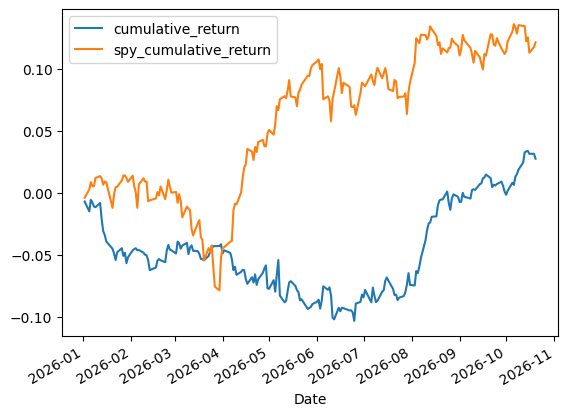

In [7]:
daily_summary[["cumulative_return", "spy_cumulative_return"]].plot()

## Regression: choose x and y

`BetaAnalysis` is imported from `risk.py`. `BetaAnalysis(x, y)` fits `y = alpha + beta * x + error`. Pass two pandas Series: x is the explanatory variable and y is the dependent variable. The class aligns their indexes and drops missing pairs; plot labels come from the Series names.

The example below uses SPY daily returns as x and long daily returns as y. Exclude the entry-day Open-to-Close observation in the calling cell; the class itself does not remove the first observation.

Use `plot_regression()` and `plot_rolling_beta(window=60)`. Inputs and fitted results are available as `.x`, `.y`, `.model`, `.alpha` and `.beta`.

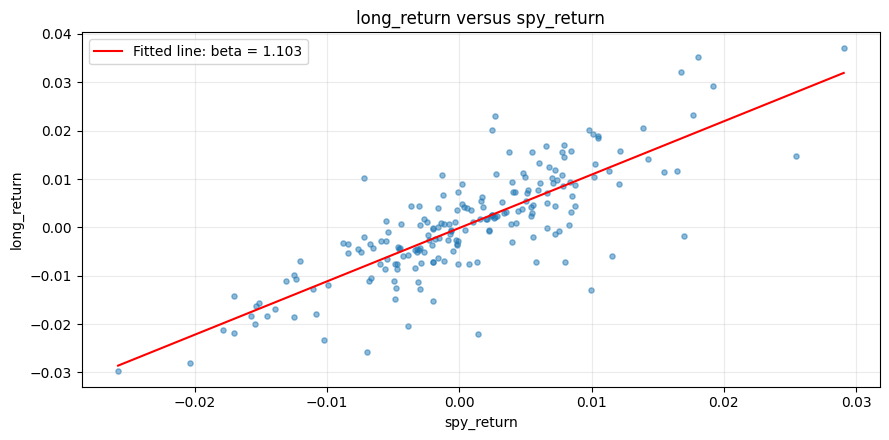

Alpha: -0.000121; beta: 1.1028


In [8]:
beta_analysis = BetaAnalysis(x=daily_summary["spy_return"].iloc[1:], y=daily_summary["long_return"].iloc[1:])
beta_analysis.plot_regression()

## Rolling beta: trailing 60 trading days

At each date, use the current paired observation and the previous 59. Fit the same `y = alpha + beta * x + error` regression within that window:

$$\beta_t=\frac{\operatorname{Cov}(y,x)_{t-59:t}}{\operatorname{Var}(x)_{t-59:t}}.$$

Move the window forward by one observation and repeat. Covariance divided by variance equals the OLS slope with an intercept. The first 59 values are missing because a full window is required. Each estimate uses data through its displayed date. The dashed line is the full-sample beta. In this example the paired data are daily trading returns, so 60 observations are 60 trading days.

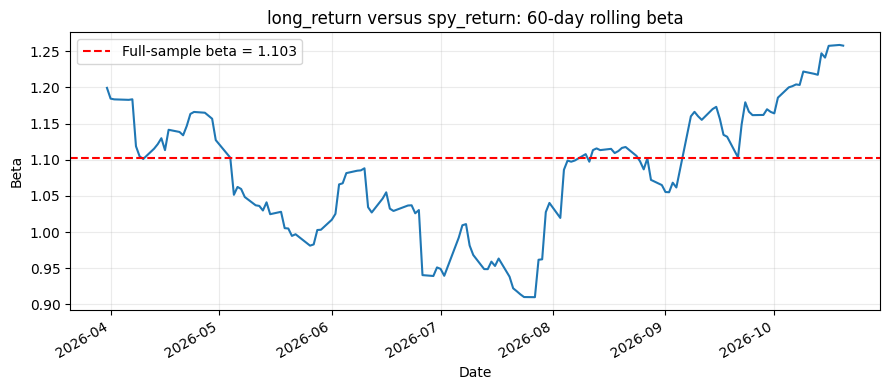

Latest rolling beta: 1.2578


In [9]:
rolling_window = 60  # Trading days
rolling_beta = beta_analysis.plot_rolling_beta(window=rolling_window)

## Baseline one-day VaR and CVaR from P&L

Use the fixed-holdings baseline `daily_summary["daily_pnl"]` directly, with **95% confidence**. Exclude the entry-day Open-to-Close observation; the remaining 200 observations are Close-to-Close daily P&L.

- **Historical**: use the observed losses (`loss = -pnl`). VaR is their empirical 95th percentile; CVaR is the average of the worst 5% probability mass, with boundary weights when needed.
- **Parametric**: assume normal P&L and estimate its mean and sample standard deviation.

All results are already in **USD**. Positive values mean losses. There is no conversion from percentages and no multiplication by exposure. This describes the observed one-day P&L sample; it is not a forward VaR backtest.

References: [VaR methods](https://www.mathworks.com/help/risk/valueatrisk.html), [expected shortfall / CVaR](https://www.mathworks.com/help/risk/expectedshortfall.html).

In [10]:
confidence = 0.95
risk_analysis = RiskAnalysis(daily_summary["daily_pnl"].iloc[1:], confidence=confidence)
risk_summary = risk_analysis.summary()

print(f"{confidence:.0%} one-day risk; observations: {len(risk_analysis.pnl)}")
display(risk_summary.rename(columns={"VaR": "VaR ($)", "CVaR": "CVaR ($)"}).round(2))

95% one-day risk; observations: 200


,VaR ($),CVaR ($)
Method,,
Historical,16483.36,24919.37
Parametric (normal),17689.64,22264.55


## Rebalance: pair or whole portfolio

`PortfolioRebalancer` is implemented in `positions.py`. Choose the replacement rule independently of the existing sizing `mode`:

- `selection_mode="pair"` (default): in each triplet, replace the losing leg, or the larger dollar loss when both lose. Keep both when neither loses.
- `selection_mode="portfolio"`: total the unrealized P&L of all currently held long assets and all currently held short assets. If either total is negative, replace every asset on the side with the larger aggregate loss. This also closes individual winners on that side. Keep both sides when neither total is negative.

Every replacement uses the currently unused A/B/C member in the same triplet and keeps the closed leg's direction. For example, with A/C held, replacing either losing leg uses B. The next check uses the updated holdings and cost bases. Each pair always has one long and one distinct short asset. In portfolio mode, the same rule replaces an entire current basket. Use `beta_column="beta"` for the frozen formation Close coefficient, or `beta_column="quote_beta"` to refit Close OLS through check_date before the next Open. The window begins at each pair's formation start and expands; no execution-day or future Close enters the fit. With `mode="strict"`, scale all planned shares down when post-replacement Open gross exceeds `2 * long_amount`. With `mode="strict_one_leg"`, scale all planned shares down by `min(1, long_amount / max(total_long, abs(total_short)))` at the scheduled execution Open. Each side then stays within `long_amount`, even if no loss replacement is selected. Round share magnitudes down to integers. Any retained-position reductions are marked `trim`. These limits apply at entry/rebalance Open; prices may move exposures above the limits between events. Borrow fee and TC are zero.

`rebalance_frequency = 3` uses completed 3-month blocks from the entry month: March, June and September Close checks, followed by next-trading-day Open execution. If no regular rebalance can execute, use the penultimate trading day's Close and the final trading day's Open. Thus `rebalance_frequency = 12` works on this incomplete 2026 sample without adding an extra final rebalance to the 3-month schedule.

`rebalance_df` contains only the initial entry and rebalance events, with **`entry_date` as its first column**. This is the shared event date for all assets, including retained positions, rather than each asset's original cost date. The initial rows show the long/short tickers entered at the first Open.

`basket` is the A/B/C membership of the actual pre-trade `ticker`. `basket_after`, placed beside it, is the membership after this event. For example, replacing NVDA with NVMI shows `basket="A"`, `basket_after="C"`, `ticker="NVDA"` and `replace_with="NVMI"`. At the next check, a held NVMI row has `basket="C"`. The internal `book` only tracks the persistent long/short position slot. `paired_ticker` identifies the other held asset. Short shares and amounts are negative; gains and losses keep their economic signs.

For rebalance rows, `ticker`, `shares`, `cost_price`, `price`, `amount` and `unrealized_pnl` describe holdings **before** trading; `price` is check-day Close. On the initial rows, `price` is entry Open and unrealized P&L is zero. `check_date` identifies this valuation date. `action` is `open`, `hold`, `replace` or `trim`; `basket_after`, `replace_with` and `shares_after` describe the resulting position. `realized_pnl` uses actual next-Open fills, which may differ from the Close loss. Full fills are in `rebalance_result["trades"]`; trade shares and amounts are positive for buys/covers and negative for sells/short sales.

Treat each block as one research year. This step records holdings and trading P&L; tax amounts are not calculated.

**Realized gains from scaling:** the loss-selection rule chooses which asset/basket to replace. Both `strict` and `strict_one_leg` sizing can also partially close profitable retained positions to meet their exposure limits. These trades have `reason="strict_cap"`, and their positive P&L is included in `cumulative_realized_gain`. The summary below explicitly identifies their realized gains. Beta mode does not make strict-cap trims. Realized gains can still occur after a Close-to-next-Open reversal, or when whole-portfolio selection closes individual winners in a losing basket.

In [11]:
rebalance_frequency = 3  # Months; use 12 for the final-two-date fallback
selection_mode = "pair"  # "pair" (default) or "portfolio"

rebalancer = PortfolioRebalancer(
    open_prices, close_prices, portfolio_A, portfolio_B, pair_betas,
    rebalance_frequency=rebalance_frequency,
    long_amount=long_amount,
    mode=mode,
    selection_mode=selection_mode,
    beta_column=beta_column,
    close_history=close_history,
)
rebalance_result = rebalancer.run()
rebalance_df = rebalance_result["history"]

In [12]:
with pd.option_context("display.max_rows", None, "display.max_columns", None):
    display(rebalance_df.round(2))

,entry_date,check_date,anchor_A,basket,basket_after,side,ticker,paired_ticker,shares,cost_price,price,amount,unrealized_pnl,action,replace_with,shares_after,realized_pnl
0,2026-01-02,2026-01-02,NVDA,A,A,long,NVDA,ANET,526,189.84,189.84,99855.84,0.00,open,,526,0.00
1,2026-01-02,2026-01-02,NVDA,B,B,short,ANET,NVDA,-822,134.05,134.05,-110189.10,-0.00,open,,-822,0.00
2,2026-01-02,2026-01-02,AAPL,A,A,long,AAPL,DAKT,367,272.26,272.26,99919.42,0.00,open,,367,0.00
3,2026-01-02,2026-01-02,AAPL,B,B,short,DAKT,AAPL,-2304,19.85,19.85,-45734.40,-0.00,open,,-2304,0.00
4,2026-01-02,2026-01-02,MSFT,A,A,long,MSFT,UBER,206,484.39,484.39,99784.34,0.00,open,,206,0.00
5,2026-01-02,2026-01-02,MSFT,B,B,short,UBER,MSFT,-733,82.04,82.04,-60135.32,-0.00,open,,-733,0.00
6,2026-01-02,2026-01-02,TSM,A,A,long,TSM,AVGO,320,311.98,311.98,99833.60,0.00,open,,320,0.00
7,2026-01-02,2026-01-02,TSM,B,B,short,AVGO,TSM,-213,352.78,352.78,-75142.14,-0.00,open,,-213,0.00
8,2026-01-02,2026-01-02,BRK-B,A,A,long,BRK-B,AIG,199,500.96,500.96,99691.04,0.00,open,,199,0.00
9,2026-01-02,2026-01-02,BRK-B,B,B,short,AIG,BRK-B,-1366,85.23,85.23,-116424.18,-0.00,open,,-1366,0.00


## Daily positions and returns after rebalancing

Use `rebalancer.calculate_daily_positions(rebalance_result)` to value the updated holdings at daily Close. Each long and short DataFrame retains all 30 tickers in A/B/C triplet order: `NVDA, ANET, NVMI, AAPL, DAKT, BELFA, ...`. Long values are positive, short values are negative and unheld values are zero. `rebalance_daily_positions` combines the two sides in one table, so each triplet's long and short assets are visible together.

`rebalance_pairs_df` lists the actual long/short tickers, their A/B/C memberships (`long_basket`, `short_basket`), signed shares, selected hedge coefficient (`beta_column`) and held share ratio after each entry/rebalance. `hedge_beta` is the selected `beta` or `quote_beta` for `long_ticker ~ short_ticker` (or the reciprocal for a reversed pair); `held_ratio = abs(short_shares) / long_shares`. The beta window is shown by `beta_start`, `beta_date` and `beta_nobs`. Dynamic beta can change even for a retained pair that is not traded; the held ratio changes only when shares change. Integer rounding and exposure scaling can also create differences. Pair-table amounts use that event's Open; daily positions use Close. Pair membership always uses updated holdings; original basket labels do not determine the next loss comparison.

On a trade day, include old positions' previous-Close-to-Open P&L and new positions' Open-to-Close P&L. Remove signed trading cash flows, including strict trims, to avoid treating exposure changes as profit. Long/short P&L use their actual signs. `short_amount` is negative; `gross_amount = long_amount + abs(short_amount)`.

Side returns divide daily P&L by the absolute previous Close amount, with initial Open amounts on day one. Combined return uses actual initial gross exposure. SPY remains the benchmark and costs remain zero.

The display below shows long positions, short positions, then their signed combined table. Separate long/short tail views hide columns that are zero throughout the displayed window; the underlying DataFrames retain all 30 tickers. The separate tables are the same positions used to calculate daily P&L.

`realized_loss` sums negative closing P&L and `realized_gain` sums positive closing P&L on each execution date, including `strict_cap` trades. Their cumulative columns keep losses and gains separate. `cumulative_realized_pnl` is the net realized result; `unrealized_pnl` is the remaining open-position P&L. At every date, `cumulative_pnl = cumulative_realized_pnl + unrealized_pnl`. These are trading P&L amounts under the model assumptions.

In [13]:
rebalance_pairs_df = rebalance_result["pairs"]
display(rebalance_pairs_df.tail(len(portfolio_A)).round(4))

,entry_date,anchor_A,long_basket,long_ticker,long_shares,short_basket,short_ticker,short_shares,hedge_beta,beta_column,beta_start,beta_date,beta_nobs,held_ratio,long_amount,short_amount
30,2026-10-01,NVDA,C,NVMI,276,B,ANET,-785,2.8403,quote_beta,2022-01-03,2026-09-30,1190,2.8442,106422.8390,-160685.5807
31,2026-10-01,AAPL,C,BELFA,269,B,DAKT,-2103,11.6234,quote_beta,2022-01-03,2026-09-30,1190,7.8178,53108.6680,-36529.1118
32,2026-10-01,MSFT,C,CDNS,228,B,UBER,-668,3.3057,quote_beta,2022-01-03,2026-09-30,1190,2.9298,77374.0767,-45784.7206
33,2026-10-01,TSM,A,TSM,291,C,FLEX,-941,3.1532,quote_beta,2022-01-03,2026-09-30,1190,3.2337,133065.5668,-104836.8134
34,2026-10-01,BRK-B,A,BRK-B,170,B,AIG,-1246,7.2734,quote_beta,2022-01-03,2026-09-30,1190,7.3294,84532.5000,-92876.8411
35,2026-10-01,JPM,A,JPM,282,B,BLX,-1505,5.3498,quote_beta,2022-01-03,2026-09-30,1190,5.3369,92707.5000,-82775.0000
36,2026-10-01,V,C,SEIC,1193,B,MUFG,-3649,3.0590,quote_beta,2022-01-03,2026-09-30,1190,3.0587,122127.4133,-82430.9106
37,2026-10-01,MA,A,MA,157,B,HLI,-340,2.1481,quote_beta,2022-01-03,2026-09-30,1190,2.1656,86507.0000,-42741.3997
38,2026-10-01,PLTR,C,NET,553,B,NYAX,-3017,5.4520,quote_beta,2022-09-21,2026-09-30,1010,5.4557,193555.5354,-146746.8782
39,2026-10-01,ORCL,B,INOD,733,A,ORCL,-425,0.5798,quote_beta,2022-01-03,2026-09-30,1190,0.5798,48744.5000,-59330.0026


In [14]:
rebalance_daily_positions_long, rebalance_daily_positions_short, rebalance_daily_summary = (
    rebalancer.calculate_daily_positions(rebalance_result)
)
rebalance_daily_positions = rebalance_daily_positions_long + rebalance_daily_positions_short

long_tail = rebalance_daily_positions_long.tail()
short_tail = rebalance_daily_positions_short.tail()
print("Long positions")
display(long_tail.loc[:, long_tail.ne(0).any()])
print("Short positions")
display(short_tail.loc[:, short_tail.ne(0).any()])
print("Combined positions")
display(rebalance_daily_positions.tail())
display(rebalance_daily_summary)
print(f"Rebalanced cumulative P&L: ${rebalance_daily_summary['cumulative_pnl'].iloc[-1]:,.2f} (realized + unrealized)")
print(f"Rebalanced return on initial gross: {rebalance_daily_summary['cumulative_return'].iloc[-1]:.2%}")

Long positions


ticker,NVMI,BELFA,CDNS,TSM,BRK-B,JPM,SEIC,MA,NET,INOD
Date,,,,,,,,,,
2026-10-14,91460.881348,48468.418030,75116.878052,125130.000000,89479.495850,94548.959656,125587.105995,94708.678467,179354.482574,38951.619553
2026-10-15,90925.440674,47551.131149,73958.641113,122874.750000,89365.598755,94619.459656,125587.105995,96762.241150,174924.964050,41465.809776
2026-10-16,88651.203369,45235.040985,72848.282227,120069.505737,90443.403320,95801.040344,124549.201820,96934.937317,163853.893250,38717.059776
2026-10-19,88071.601685,46628.459015,74296.076660,122284.020355,90479.096680,94055.459656,125014.471092,96774.803833,164561.732574,39582.000000
2026-10-20,88328.279663,46187.299179,72930.358887,123698.276093,91769.401245,94543.322754,127829.951820,97405.937317,161304.571350,40351.649441


Short positions


ticker,ANET,DAKT,UBER,FLEX,AIG,BLX,MUFG,HLI,NYAX,ORCL
Date,,,,,,,,,,
2026-10-14,-153404.698563,-37664.729679,-46285.720612,-94429.348564,-96477.780380,-82127.849541,-79840.116938,-42425.199585,-134890.067238,-55483.751297
2026-10-15,-145680.301437,-38421.810963,-47608.357758,-92688.500000,-98583.523422,-81917.150459,-79767.142227,-43693.398132,-135131.432762,-57149.750519
2026-10-16,-138929.296646,-38295.628075,-46993.798981,-85122.859138,-100602.037338,-82278.347244,-79840.116938,-44047.001038,-138450.128159,-54497.748184
2026-10-19,-143615.747604,-39136.831284,-46733.279388,-82375.140862,-100502.364563,-82413.797474,-79037.339443,-43203.799896,-139777.615524,-55075.748444
2026-10-20,-142234.151917,-39788.760160,-46051.921631,-82328.087990,-102022.476578,-83873.649311,-78307.536659,-44312.200623,-146596.030460,-55734.499741


Combined positions


ticker,NVDA,ANET,NVMI,AAPL,DAKT,BELFA,MSFT,UBER,CDNS,TSM,...,SEIC,MA,HLI,BAM,PLTR,NYAX,NET,ORCL,INOD,GWRE
Date,,,,,,,,,,,,,,,,,,,,,
2026-10-14,0.0,-153404.698563,91460.881348,0.0,-37664.729679,48468.418030,0.0,-46285.720612,75116.878052,125130.000000,...,125587.105995,94708.678467,-42425.199585,0.0,0.0,-134890.067238,179354.482574,-55483.751297,38951.619553,0.0
2026-10-15,0.0,-145680.301437,90925.440674,0.0,-38421.810963,47551.131149,0.0,-47608.357758,73958.641113,122874.750000,...,125587.105995,96762.241150,-43693.398132,0.0,0.0,-135131.432762,174924.964050,-57149.750519,41465.809776,0.0
2026-10-16,0.0,-138929.296646,88651.203369,0.0,-38295.628075,45235.040985,0.0,-46993.798981,72848.282227,120069.505737,...,124549.201820,96934.937317,-44047.001038,0.0,0.0,-138450.128159,163853.893250,-54497.748184,38717.059776,0.0
2026-10-19,0.0,-143615.747604,88071.601685,0.0,-39136.831284,46628.459015,0.0,-46733.279388,74296.076660,122284.020355,...,125014.471092,96774.803833,-43203.799896,0.0,0.0,-139777.615524,164561.732574,-55075.748444,39582.000000,0.0
2026-10-20,0.0,-142234.151917,88328.279663,0.0,-39788.760160,46187.299179,0.0,-46051.921631,72930.358887,123698.276093,...,127829.951820,97405.937317,-44312.200623,0.0,0.0,-146596.030460,161304.571350,-55734.499741,40351.649441,0.0


,long_amount,short_amount,gross_amount,long_pnl,short_pnl,long_return,short_return,daily_pnl,cumulative_pnl,daily_return,...,realized_loss,realized_gain,realized_pnl,cumulative_realized_loss,cumulative_realized_gain,cumulative_realized_pnl,unrealized_pnl,spy_close,spy_return,spy_cumulative_return
Date,,,,,,,,,,,,,,,,,,,,,
2026-01-02,9.870832e+05,-852658.374034,1.839742e+06,-11379.326294,-1018.726153,-0.011397,-0.001196,-12398.052447,-12398.052447,-0.006701,...,0.0,0.0,0.0,0.000000,0.000000,0.00000,-12398.052447,683.169983,-0.003704,-0.003704
2026-01-05,9.939998e+05,-874286.233599,1.868286e+06,6916.600037,-21627.859565,0.007007,-0.025365,-14711.259528,-27109.311975,-0.007952,...,0.0,0.0,0.0,0.000000,0.000000,0.00000,-27109.311975,687.719971,0.006660,0.002931
2026-01-06,1.001687e+06,-864761.544617,1.866448e+06,7687.032928,9524.688982,0.007733,0.010894,17211.721910,-9897.590065,0.009303,...,0.0,0.0,0.0,0.000000,0.000000,0.00000,-9897.590065,691.809998,0.005947,0.008896
2026-01-07,9.972747e+05,-864368.040005,1.861643e+06,-4412.206100,393.504612,-0.004405,0.000455,-4018.701488,-13916.291553,-0.002172,...,0.0,0.0,0.0,0.000000,0.000000,0.00000,-13916.291553,689.580017,-0.003223,0.005644
2026-01-08,9.896523e+05,-862825.665213,1.852478e+06,-7622.399979,1542.374792,-0.007643,0.001784,-6080.025187,-19996.316740,-0.003286,...,0.0,0.0,0.0,0.000000,0.000000,0.00000,-19996.316740,689.510010,-0.000102,0.005542
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-10-14,9.628065e+05,-823029.262396,1.785836e+06,-25818.215191,26354.865656,-0.026115,0.031028,536.650465,-71098.491242,0.000290,...,0.0,0.0,0.0,-343965.201913,20669.000973,-323296.20094,252197.709698,769.599976,-0.010810,0.122340
2026-10-15,9.580351e+05,-820641.367680,1.778677e+06,-4771.377205,2387.894716,-0.004956,0.002901,-2383.482489,-73481.973731,-0.001288,...,0.0,0.0,0.0,-343965.201913,20669.000973,-323296.20094,249814.227209,771.789978,0.002846,0.125534
2026-10-16,9.371036e+05,-809056.961740,1.746161e+06,-20931.574173,11584.405939,-0.021848,0.014116,-9347.168234,-82829.141965,-0.005052,...,0.0,0.0,0.0,-343965.201913,20669.000973,-323296.20094,240467.058975,763.250000,-0.011065,0.113080


Rebalanced cumulative P&L: $-87,776.02 (realized + unrealized)
Rebalanced return on initial gross: -4.74%


In [15]:
pnl_columns = [
    "cumulative_realized_loss", "cumulative_realized_gain",
    "cumulative_realized_pnl", "unrealized_pnl", "cumulative_pnl",
]
pnl_summary = rebalance_daily_summary.iloc[-1][pnl_columns].to_frame("USD")
display(pnl_summary.round(2))

# Both strict modes can close profitable retained positions when scaling.
scale_realized_gain = rebalance_result["trades"].loc[
    rebalance_result["trades"]["reason"].eq("strict_cap"), "realized_pnl"
].clip(lower=0).sum()
if scale_realized_gain > 0:
    print(f"{mode} scaling realized ${scale_realized_gain:,.2f} in gains by reducing profitable positions.")
    print("These gains are included in cumulative_realized_gain.")

,USD
cumulative_realized_loss,-343965.20
cumulative_realized_gain,20669.00
cumulative_realized_pnl,-323296.20
unrealized_pnl,235520.19
cumulative_pnl,-87776.02


strict_one_leg scaling realized $20,669.00 in gains by reducing profitable positions.
These gains are included in cumulative_realized_gain.


<Axes: xlabel='Date'>

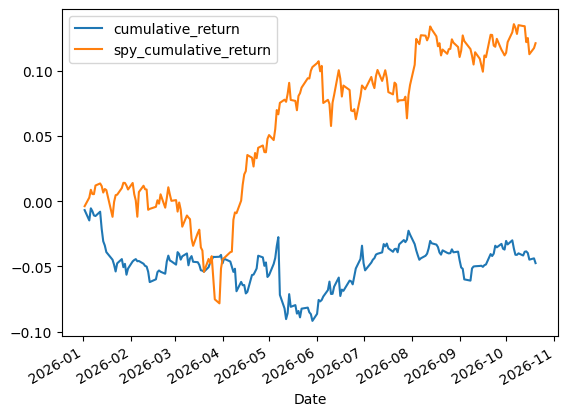

In [16]:
rebalance_daily_summary[["cumulative_return", "spy_cumulative_return"]].plot()

## Rebalanced portfolio beta versus SPY

Use the existing `BetaAnalysis` class with SPY returns as x and rebalanced strategy returns as y. The default `daily_return` measures the entire long/short strategy; change `rebalance_beta_y` to `long_return` or `short_return` to inspect one side. Exclude the initial Open-to-Close observation. Rolling beta uses the same trailing 60 paired observations as above.

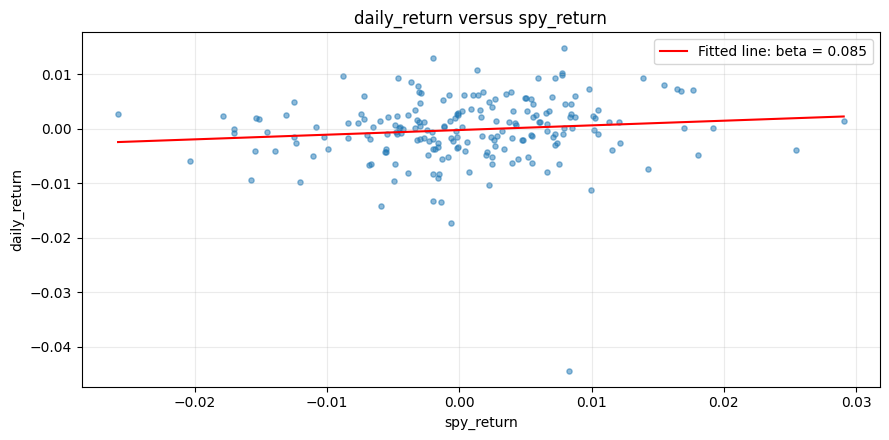

Alpha: -0.000257; beta: 0.0855


In [17]:
rebalance_beta_y = "daily_return"  # "daily_return", "long_return" or "short_return"
rebalance_beta_analysis = BetaAnalysis(
    x=rebalance_daily_summary["spy_return"].iloc[1:],
    y=rebalance_daily_summary[rebalance_beta_y].iloc[1:],
)
rebalance_beta_analysis.plot_regression()

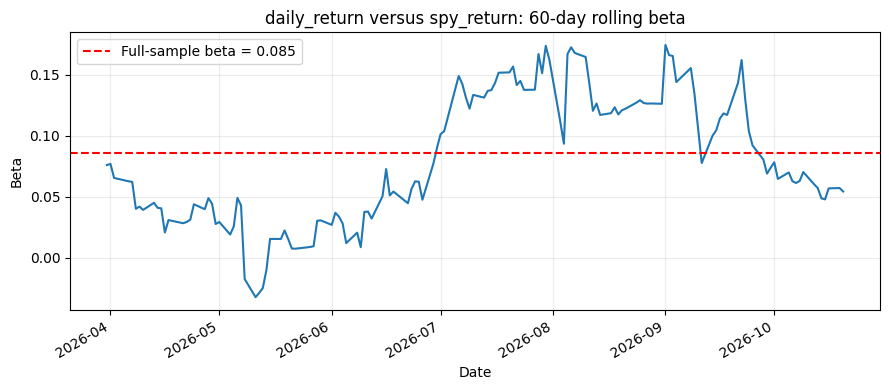

Latest rolling beta: 0.0542


In [18]:
rebalance_rolling_beta = rebalance_beta_analysis.plot_rolling_beta(window=rolling_window)